<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/practices/California_Housing_cat_num_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 5. BaseEstimator, TransformerMixin 사용자정의 함수와 파이프라인
### BaseExtimator, TranformarMxin, Class, inheritance
#### [CategoricalEncoder](https://feature-engine.trainindata.com/en/1.8.x/user_guide/encoding/index.html)
#### put-customized-functions-in-sklearn-pipeline
https://stackoverflow.com/questions/31259891/put-customized-functions-in-sklearn-pipeline

# Get the data

In [6]:
from sklearn.datasets import fetch_california_housing
fetch_california_housing()

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [10]:
df = fetch_california_housing()
df.feature_names.extend(df.target_names)
housing = pd.DataFrame(np.c_[df.data, df.target], columns = df.feature_names)
housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


# Discover and visualize the data to gain insights

<Axes: xlabel='Longitude', ylabel='Latitude'>

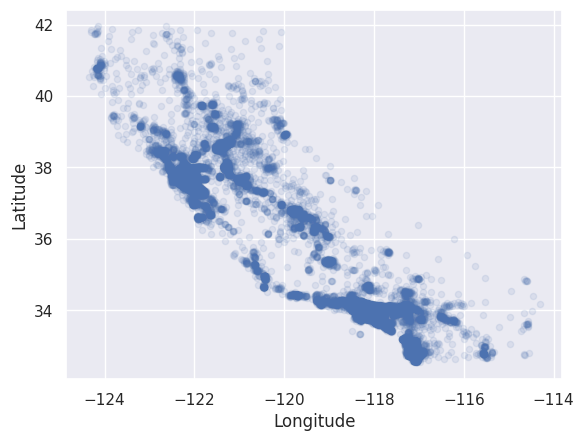

In [12]:
housing.plot(kind="scatter", x="Longitude", y="Latitude", alpha=0.1)

The argument `sharex=False` fixes a display bug (the x-axis values and legend were not displayed). This is a temporary fix (see: https://github.com/pandas-dev/pandas/issues/10611 ). Thanks to Wilmer Arellano for pointing it out.

<Axes: xlabel='Longitude', ylabel='Latitude'>

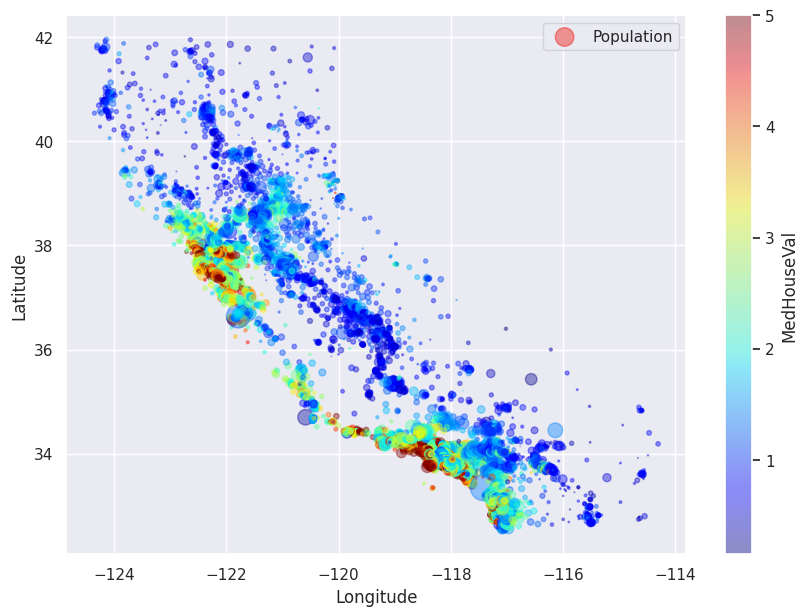

In [13]:
housing.plot(kind="scatter", x="Longitude", y="Latitude", alpha=0.4,
    s=housing["Population"]/100, label="Population", figsize=(10,7),
    c="MedHouseVal", cmap=plt.get_cmap("jet"), colorbar=True,
    sharex=False)
plt.legend()

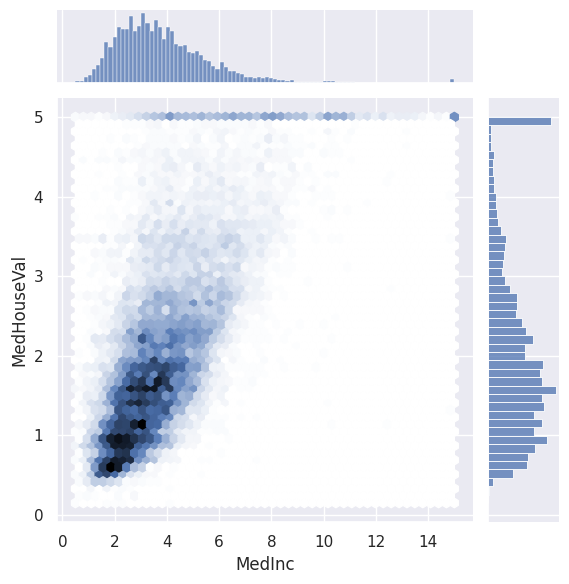

In [16]:
sns.jointplot(x="MedInc", y="MedHouseVal", data=housing, kind="hex")

In [23]:
housing.corr().style.background_gradient(cmap='coolwarm')

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


# Prepare the data for Machine Learning algorithms

In [18]:
X = housing.drop(['Latitude', 'Longitude', 'MedHouseVal'], axis=1)
y = housing['MedHouseVal']
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467


In [24]:
from sklearn.base import BaseEstimator, TransformerMixin

rooms_ix, bedrooms_ix, population_ix, households_ix = 1, 2, 3, 4

class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self):
        pass
    def fit(self, X, y=None):
        return self  # nothing else to do
    def transform(self, X, y=None):
        rooms_per_household = X[:, rooms_ix] / X[:, households_ix]
        population_per_household = X[:, population_ix] / X[:, households_ix]
        return np.c_[X, rooms_per_household, population_per_household]

attr_adder = CombinedAttributesAdder()
X_extra_attribs = attr_adder.transform(X.values)
X_extra_attribs = pd.DataFrame(
    X_extra_attribs,
    columns=list(X.columns)+["rooms_per_household", "population_per_household"],
    index=housing.index)

X_extra_attribs.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,rooms_per_household,population_per_household
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,0.127329,0.003180
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,0.008746,0.000405
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,0.104839,0.002164
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,0.093190,0.001923
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,0.092035,0.001913


### Now let's build a pipeline for preprocessing the numerical attributes:

In [26]:
from sklearn.impute import SimpleImputer
# 'ocean_proximity' 열이 없을 경우 에러를 무시하고 진행하도록 errors='ignore' 추가
X_num = X.drop(['ocean_proximity'], axis=1, errors='ignore')

num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('attribs_adder', CombinedAttributesAdder()),
        ('std_scaler', StandardScaler()),
    ])

X_num_tr = num_pipeline.fit_transform(X_num)
X_num_tr = pd.DataFrame(
    X_num_tr,
    columns=list(X_num.columns)+["rooms_per_household",
                                 "population_per_household"],
    index=housing.index)
X_num_tr.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,rooms_per_household,population_per_household
0,2.344766,0.982143,0.628559,-0.153758,-0.974429,-0.049597,0.647204,0.108048
1,2.332238,-0.607019,0.327041,-0.263336,0.861439,-0.092512,-0.247146,-0.113906
2,1.782699,1.856182,1.155620,-0.049016,-0.820777,-0.025843,0.477581,0.026831
3,0.932968,1.856182,0.156966,-0.049833,-0.766028,-0.050329,0.389727,0.007541
4,-0.012881,1.856182,0.344711,-0.032906,-0.759847,-0.085616,0.381019,0.006770


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

num_attribs = list(X_num)
# X에 'ocean_proximity'가 실제로 존재하는지 확인 후 처리
cat_attribs = ["ocean_proximity"] if "ocean_proximity" in X.columns else []

transformer_list = [("num", num_pipeline, num_attribs)]
if cat_attribs:
    transformer_list.append(("cat", OneHotEncoder(), cat_attribs))

full_pipeline = ColumnTransformer(transformer_list)

X_prepared = full_pipeline.fit_transform(X)
X_prepared

array([[ 2.34476576,  0.98214266,  0.62855945, ..., -0.04959654,
         0.64720445,  0.1080476 ],
       [ 2.33223796, -0.60701891,  0.32704136, ..., -0.09251223,
        -0.24714597, -0.11390606],
       [ 1.7826994 ,  1.85618152,  1.15562047, ..., -0.02584253,
         0.47758148,  0.02683116],
       ...,
       [-1.14259331, -0.92485123, -0.09031802, ..., -0.0717345 ,
        -0.18578833, -0.05731082],
       [-1.05458292, -0.84539315, -0.04021111, ..., -0.09122515,
        -0.12990468, -0.01977674],
       [-0.78012947, -1.00430931, -0.07044252, ..., -0.04368215,
        -0.22610885, -0.07925512]], shape=(20640, 8))

In [30]:
print(full_pipeline)
print(full_pipeline.named_transformers_)

# 'cat' 변환기가 존재할 때만 출력하도록 예외 처리
if "cat" in full_pipeline.named_transformers_:
    print(full_pipeline.named_transformers_["cat"].categories_[0])
else:
    print("데이터셋에 범주형 특성('ocean_proximity')이 존재하지 않아 'cat' 변환기가 생성되지 않았습니다.")

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('attribs_adder',
                                                  CombinedAttributesAdder()),
                                                 ('std_scaler',
                                                  StandardScaler())]),
                                 ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms',
                                  'Population', 'AveOccup'])])
{'num': Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('attribs_adder', CombinedAttributesAdder()),
                ('std_scaler', StandardScaler())])}
데이터셋에 범주형 특성('ocean_proximity')이 존재하지 않아 'cat' 변환기가 생성되지 않았습니다.


In [31]:
from sklearn.ensemble import RandomForestRegressor
forest_reg = RandomForestRegressor()
param_grid = [
{'n_estimators': [3, 10, 30], 'max_features': [2, 4, 6, 8]},
{'bootstrap': [False], 'n_estimators': [3, 10], 'max_features': [2, 3, 4]},
]
grid_search = RandomizedSearchCV(forest_reg, param_grid, cv=5,
                                 scoring='neg_mean_squared_error')
grid_search.fit(X_prepared, y)
grid_search.best_estimator_

RandomizedSearchCV(cv=5, estimator=RandomForestRegressor(),
                   param_distributions=[{'max_features': [2, 4, 6, 8],
                                         'n_estimators': [3, 10, 30]},
                                        {'bootstrap': [False],
                                         'max_features': [2, 3, 4],
                                         'n_estimators': [3, 10]}],
                   scoring='neg_mean_squared_error')

RandomForestRegressor(max_features=4, n_estimators=30)

In [32]:
grid_search.best_params_

cvres = grid_search.cv_results_
for mean_score, params in zip(cvres["mean_test_score"], cvres["params"]):
    print(np.sqrt(-mean_score), params)

{'n_estimators': 30, 'max_features': 4}

0.6814599784124938 {'n_estimators': 30, 'max_features': 4}
0.7779713345122646 {'n_estimators': 3, 'max_features': 6}
0.714465114056435 {'n_estimators': 10, 'max_features': 2}
0.7166159094833597 {'n_estimators': 10, 'max_features': 2, 'bootstrap': False}
0.7072181390867514 {'n_estimators': 10, 'max_features': 4}
0.8028731964380328 {'n_estimators': 3, 'max_features': 2}
0.7069629305314454 {'n_estimators': 10, 'max_features': 6}
0.7805316697154117 {'n_estimators': 3, 'max_features': 8}
0.6888860123342083 {'n_estimators': 30, 'max_features': 8}
0.7799976517769605 {'n_estimators': 3, 'max_features': 4, 'bootstrap': False}


In [33]:
best_params = grid_search.best_params_
tuned_params = {item[:]: best_params[item] for item in best_params}
model= RandomForestRegressor().set_params(**tuned_params)
model.fit(X_prepared, y)

RandomForestRegressor(max_features=4, n_estimators=30)

In [35]:
extra_attribs = ["rooms_per_hhold", "pop_per_hhold", "bedrooms_per_room"]

# 'cat' 변환기가 존재할 때만 범주형 속성을 추가하도록 처리
if "cat" in full_pipeline.named_transformers_:
    cat_encoder = full_pipeline.named_transformers_["cat"]
    cat_one_hot_attribs = list(cat_encoder.categories_[0])
else:
    cat_one_hot_attribs = []

attributes = num_attribs + extra_attribs + cat_one_hot_attribs

# 중요도 정렬 시 특성 개수와 일치하는지 안전하게 매핑
sorted(zip(model.feature_importances_, attributes), reverse=True)

[(np.float64(0.4753047091750177), 'MedInc'),
 (np.float64(0.1449733583779079), 'AveOccup'),
 (np.float64(0.13348526768244628), 'AveRooms'),
 (np.float64(0.07160299525386393), 'HouseAge'),
 (np.float64(0.05940678306244208), 'AveBedrms'),
 (np.float64(0.040515347913060225), 'rooms_per_hhold'),
 (np.float64(0.038232875881053924), 'Population'),
 (np.float64(0.03647866265420793), 'pop_per_hhold')]

<BarContainer object of 8 artists>

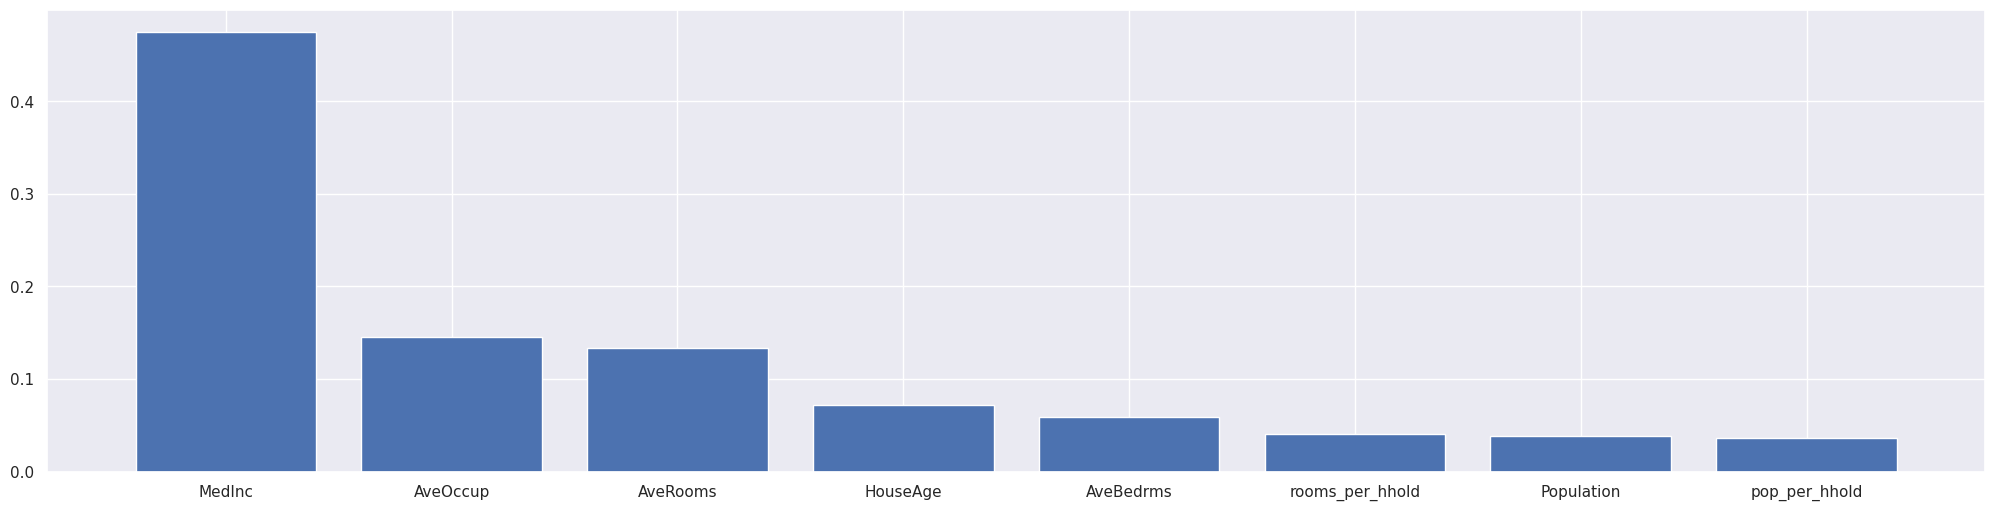

In [36]:
im = dict(sorted(zip(model.feature_importances_, attributes), reverse=True))
plt.rcParams['figure.figsize'] = [25, 6]
plt.bar(list(im.values()), list(im.keys()), align='center')

## 6. One-hot coding 선형 회귀 예측
Random effects and fixed effects

,city,year,rent,rent_mean_city
0,Bangaluru,2010,2499,2500
1,Bangaluru,2011,2500,2500
2,Bangaluru,2012,2501,2500
3,Seoul,2010,3499,3500
4,Seoul,2011,3500,3500
5,Seoul,2012,3501,3500
6,Vancouber,2010,3999,4000
7,Vancouber,2011,4000,4000
8,Vancouber,2012,4001,4000


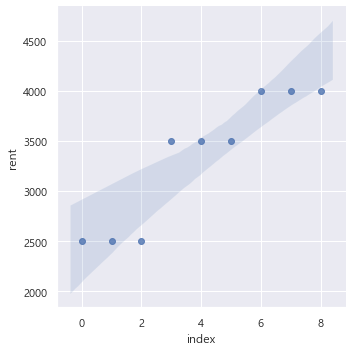

In [ ]:
city = ['Bangaluru']*3 + ['Seoul']*3 + ['Vancouber']*3
year = [2010, 2011, 2012]*3
rent =[2499, 2500, 2501, 3499, 3500, 3501, 3999, 4000, 4001]
df = pd.DataFrame(zip(city, year, rent), columns = ['city', 'year', 'rent'])
map_mean = df.groupby(['city'])['rent'].mean().to_dict()
df['rent_mean_city'] = df['city'].map(map_mean)
df
sns.lmplot(x='index', y='rent', data=df.reset_index())

## one_hot encoding

In [ ]:
one_hot_df = pd.get_dummies(df, prefix=['city'])
one_hot_df['city'] = df['city']

X = one_hot_df[['city_Bangaluru', 'city_Seoul', 'city_Vancouber']]
y = one_hot_df['rent']

LinearRegression()

3333.3333333333335

array([-833.33333333,  166.66666667,  666.66666667])

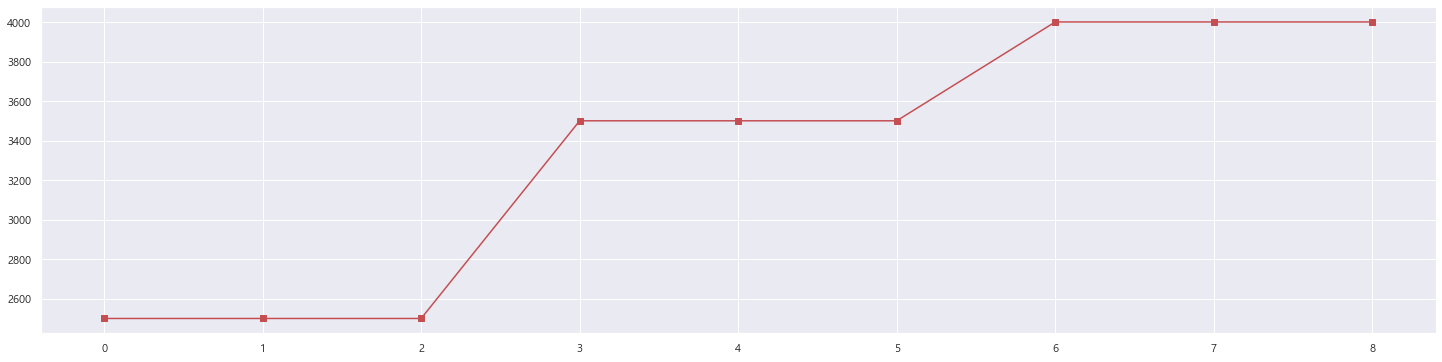

In [ ]:
from sklearn import linear_model
model= linear_model.LinearRegression()
model.fit(X, y)
model.intercept_; model.coef_
var_predict = X.values@model.coef_.reshape(-1,1)
one_hot_df['predict'] = model.intercept_ + var_predict
plt.plot(one_hot_df.index, one_hot_df['predict'], marker='s', color='r')

In [ ]:
df['rent'].mean()
model.intercept_

3333.3333333333335

3333.3333333333335

## dummy

In [ ]:
dummy_df = pd.get_dummies(df, prefix=['city'], drop_first=True)
dummy_df['city'] = df['city']
dummy_df
model.fit(dummy_df.iloc[:, 3:5], dummy_df['rent'])
model.intercept_; model.coef_

,year,rent,rent_mean_city,city_Seoul,city_Vancouber,city
0,2010,2499,2500,0,0,Bangaluru
1,2011,2500,2500,0,0,Bangaluru
2,2012,2501,2500,0,0,Bangaluru
3,2010,3499,3500,1,0,Seoul
4,2011,3500,3500,1,0,Seoul
5,2012,3501,3500,1,0,Seoul
6,2010,3999,4000,0,1,Vancouber
7,2011,4000,4000,0,1,Vancouber
8,2012,4001,4000,0,1,Vancouber


LinearRegression()

2500.0000000000005

array([1000., 1500.])

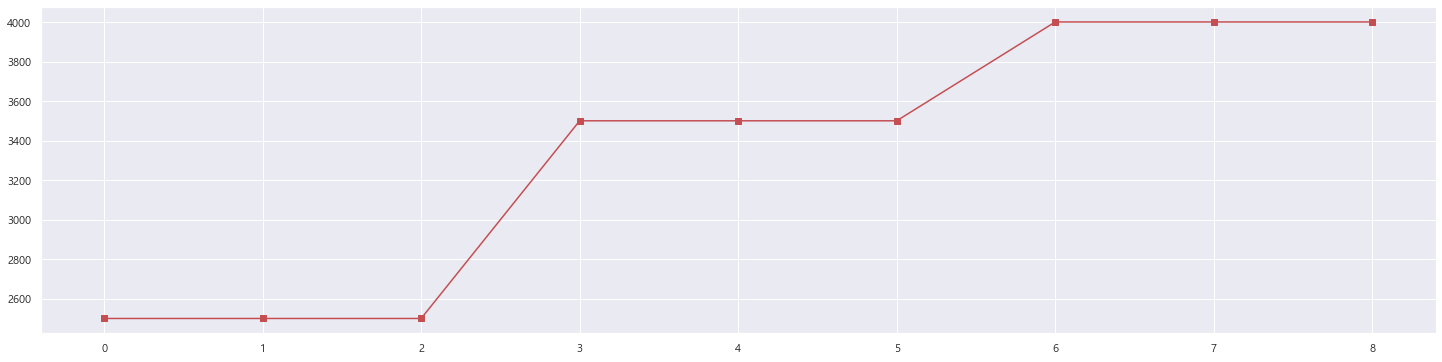

In [ ]:
var_predict = dummy_df.iloc[:, 3:5].values@model.coef_.reshape(-1,1)
dummy_df['predict'] = model.intercept_ + var_predict
plt.plot(dummy_df.index, dummy_df['predict'], marker='s', color='r')

In [ ]:
model.intercept_
df[df['city'] == 'Bangaluru']['rent'].mean()
df[df['city'] == 'Seoul']['rent'].mean()
df[df['city'] == 'Vancouber']['rent'].mean()

2500.0000000000005

2500.0

3500.0

4000.0

### Effect Coding

In [ ]:
effect_df = dummy_df.copy()
effect_df.loc[0:2, ['city_Seoul', 'city_Vancouber']] = -1.0
effect_df
model.fit(effect_df[['city_Seoul', 'city_Vancouber']], effect_df['rent'])
model.intercept_; model.coef_

,year,rent,rent_mean_city,city_Seoul,city_Vancouber,city,predict
0,2010,2499,2500,-1.0,-1.0,Bangaluru,2500.0
1,2011,2500,2500,-1.0,-1.0,Bangaluru,2500.0
2,2012,2501,2500,-1.0,-1.0,Bangaluru,2500.0
3,2010,3499,3500,1.0,0.0,Seoul,3500.0
4,2011,3500,3500,1.0,0.0,Seoul,3500.0
5,2012,3501,3500,1.0,0.0,Seoul,3500.0
6,2010,3999,4000,0.0,1.0,Vancouber,4000.0
7,2011,4000,4000,0.0,1.0,Vancouber,4000.0
8,2012,4001,4000,0.0,1.0,Vancouber,4000.0


LinearRegression()

3333.3333333333335

array([166.66666667, 666.66666667])

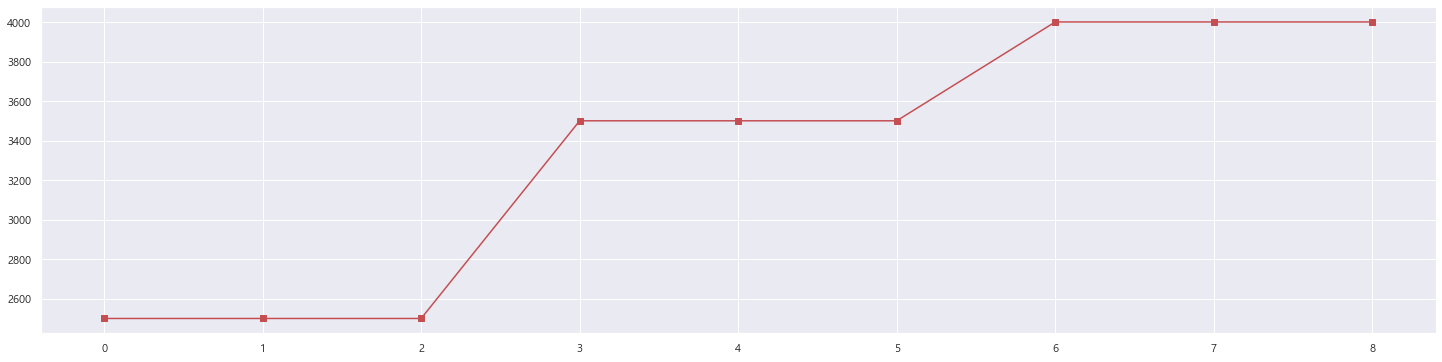

In [ ]:
var_predict = effect_df.iloc[:, 3:5].values@model.coef_.reshape(-1,1)
effect_df['predict'] = model.intercept_ + var_predict
plt.plot(effect_df.index, effect_df['predict'], marker='s', color='r')

Variation for dependents and regressors
- overall variation; variation over time and individuals
- between variation; variation between individuals
- within deviation; variation within individuals (over time)

In [ ]:
df['overall_mean'] = df['rent'].mean()
df['overall_deviation'] =  df['rent'] - df['overall_mean']
df['between_deviation'] = df['rent_mean_city'] - df['overall_mean']
df['within_deviation'] = df['rent'] - df['rent_mean_city']
df.round(2)

,city,year,rent,rent_mean_city,overall_mean,overall_deviation,between_deviation,within_deviation
0,Bangaluru,2010,2499,2500,3333.33,-834.33,-833.33,-1
1,Bangaluru,2011,2500,2500,3333.33,-833.33,-833.33,0
2,Bangaluru,2012,2501,2500,3333.33,-832.33,-833.33,1
3,Seoul,2010,3499,3500,3333.33,165.67,166.67,-1
4,Seoul,2011,3500,3500,3333.33,166.67,166.67,0
5,Seoul,2012,3501,3500,3333.33,167.67,166.67,1
6,Vancouber,2010,3999,4000,3333.33,665.67,666.67,-1
7,Vancouber,2011,4000,4000,3333.33,666.67,666.67,0
8,Vancouber,2012,4001,4000,3333.33,667.67,666.67,1


## 7. Sweetviz

In [ ]:
import sweetviz
titanic = sns.load_dataset('titanic')
for col in titanic.select_dtypes(include=['category']).columns :
    titanic[col] = titanic[col].astype('object')
train, test = train_test_split(titanic, test_size = 0.2, random_state = 11)

In [ ]:
titanic = sns.load_dataset('titanic')
titanic = titanic.drop(['who', 'adult_male', 'alive', 'alone'], axis = 1)
for col in titanic.select_dtypes(include=['category']).columns :
    titanic[col] = titanic[col].astype('object')
train, test = train_test_split(titanic, test_size = 0.2, random_state = 11)

In [ ]:
my_report = sweetviz.compare([train, 'Train'], [test, 'Test'], 'survived')
my_report.show_html('../output/Report.html')

:FEATURES DONE:                    |█████████████████████| [100%]   00:02  -> (00:00 left)
:PAIRWISE DONE:                    |█████████████████████| [100%]   00:00  -> (00:00 left)


Creating Associations graph... DONE!


In [ ]:
feature_config = sweetviz.FeatureConfig(skip=['deck'], force_cat=['sex'])
my_report = sweetviz.compare([train, 'Train'], [test, 'Test'], 'survived',
                             feature_config)
my_report.show_html('../output/Report_01.html')

:FEATURES DONE:                    |█████████████████████| [100%]   00:01  -> (00:00 left)
:PAIRWISE DONE:                    |█████████████████████| [100%]   00:00  -> (00:00 left)


Creating Associations graph... DONE!


In [ ]:
train.sex.value_counts()
train.sex.value_counts(normalize=True)*100
train[train.sex == 'female']['survived'].value_counts(normalize=True)*100

male      459
female    253
Name: sex, dtype: int64

male      64.466292
female    35.533708
Name: sex, dtype: float64

1    73.913043
0    26.086957
Name: survived, dtype: float64

In [ ]:
my_report = sweetviz.compare_intra(train, train['sex'] == 'male', ['Male', 'Female'],
                                   'survived')
my_report.show_html('../output/Report_02.html')

:FEATURES DONE:                    |█████████████████████| [100%]   00:02  -> (00:00 left)
:PAIRWISE DONE:                    |█████████████████████| [100%]   00:00  -> (00:00 left)


Creating Associations graph... DONE!


## 8. PyCaret

In [ ]:
from pycaret.datasets import get_data
diabetes = get_data('diabetes')
diabetes.shape

,Number of times pregnant,Plasma glucose concentration a 2 hours in an oral glucose tolerance test,Diastolic blood pressure (mm Hg),Triceps skin fold thickness (mm),2-Hour serum insulin (mu U/ml),Body mass index (weight in kg/(height in m)^2),Diabetes pedigree function,Age (years),Class variable
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


(768, 9)

In [ ]:
from pycaret.classification import *
clf1 = setup(data = diabetes, target = 'Class variable')

Setup Succesfully Completed!


,Description,Value
0,session_id,5740
1,Target Type,Binary
2,Label Encoded,None
3,Original Data,"(768, 9)"
4,Missing Values,False
5,Numeric Features,7
6,Categorical Features,1
7,Ordinal Features,False
8,High Cardinality Features,False
9,High Cardinality Method,None


In [ ]:
compare_models()

IntProgress(value=0, description='Processing: ', max=176)

,,
,,
Initiated,. . . . . . . . . . . . . . . . . .,15:16:59
Status,. . . . . . . . . . . . . . . . . .,Fitting Fold 1 of 10
Estimator,. . . . . . . . . . . . . . . . . .,Naive Bayes
ETC,. . . . . . . . . . . . . . . . . .,Calculating ETC


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
0,Logistic Regression,0.7580,0.8070,0.5406,0.7061,0.6070,0.4374,0.4489,0.0308
1,K Neighbors Classifier,0.7132,0.7452,0.5351,0.6033,0.5602,0.3509,0.3563,0.0031


FloatingPointError: underflow encountered in exp

In [ ]:
lr = create_model('lr')

In [ ]:
tunes_lr = tune_model(lr)
tunes_lr

In [ ]:
evaluate_model(lr)

In [ ]:
pred_holdout = predict_model(lr)
pred_holdout.shape
pred_holdout.iloc[:, 20:27]

In [ ]:
final_lr = finalize_model(lr)
final_lr

In [ ]:
df = pd.read_pickle('../data/4장자료_01.pkl')
df.rename(columns={'성별':'sex', '연령':'age', '지역':'region',
                   '직업':'job', '가구소득':'income', '학력':'school',
                   '주거형태':'house', '결혼':'marriage', '자녀수':'kids',
                   '인터넷평일':'iw', '인터넷주말':'is', '인터넷휴일':'ih',
                   '모바일평일':'mw', '모바일주말':'ms', '모바일휴일':'mh'
                  }, inplace =True)
df.head()

,sex,age,region,job,income,school,house,marriage,kids,iw,is,ih,mw,ms,mh,연령대,drama1,drama2,drama3,drama4,drama5,drama6,drama7,drama8,drama9,drama10,drama11,drama12,drama13,drama14,drama15,drama16,tv1,tv2,tv3,tv4,tv5,tv6,tv7,tv8,tv9,tv10,tv11,tv12,tv13,tv14,tv15,tv16,tv17,구매
0,1,14.0,서울,학생재수생,6.0,중학교재학,월세,미혼,0.0,0.000000,120.000000,120.000000,180.0,12.247449,13.416408,1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,1,14.0,서울,학생재수생,6.0,중학교재학,자가,미혼,0.0,30.000000,40.000000,40.000000,30.0,6.324555,6.324555,1,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,1,14.0,서울,학생재수생,6.0,중학교재학,전세,미혼,0.0,90.000000,60.000000,60.000000,120.0,13.416408,13.416408,1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,1,14.0,서울,학생재수생,8.0,중학교재학,자가,미혼,0.0,68.876933,73.094149,69.866846,60.0,7.745967,7.745967,1,1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
4,1,14.0,서울,학생재수생,9.0,중학교재학,자가,미혼,0.0,0.000000,60.000000,60.000000,180.0,13.416408,13.416408,1,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0


In [ ]:
categorical_list = list(df.select_dtypes(include=['category']).columns)
df = pd.get_dummies(df, prefix= categorical_list)
clf = setup(data = df, target = '구매', normalize = True)

Setup Succesfully Completed!


,Description,Value
0,session_id,2665
1,Target Type,Binary
2,Label Encoded,None
3,Original Data,"(3997, 86)"
4,Missing Values,False
5,Numeric Features,54
6,Categorical Features,31
7,Ordinal Features,False
8,High Cardinality Features,False
9,High Cardinality Method,None


In [ ]:
compare_models()

IntProgress(value=0, description='Processing: ', max=176)

,,
,,
Initiated,. . . . . . . . . . . . . . . . . .,15:16:59
Status,. . . . . . . . . . . . . . . . . .,Fitting Fold 1 of 10
Estimator,. . . . . . . . . . . . . . . . . .,Naive Bayes
ETC,. . . . . . . . . . . . . . . . . .,Calculating ETC


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
0,Logistic Regression,0.6764,0.6834,0.3192,0.5598,0.4056,0.2061,0.2217,0.0547
1,K Neighbors Classifier,0.6468,0.6205,0.3512,0.4909,0.4086,0.1665,0.1718,0.0535


FloatingPointError: underflow encountered in exp